In [161]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chi2_contingency
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest, proportion_confint


In [155]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 31.5 MB/s  0:00:0031.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [statsmodels] 3/4 [statsmodels]

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Считываем данные с экселя

In [17]:
sheets = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name=["Пользователи", "Платежи"])

# Достаем DataFrame по ключам
users = sheets["Пользователи"]
payments = sheets["Платежи"]

In [5]:
pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


In [41]:
users = users.dropna()

In [42]:
users.groupby('group').count()

,user_id,age,city,device_type
group,,,,
A,751,751,751,751
B,751,751,751,751


In [47]:
print(users.describe())
print(users.head())

           user_id          age
count  1502.000000  1502.000000
mean   1760.156458    32.752330
std     507.303636     8.413841
min    1001.000000    -5.000000
25%    1376.250000    27.000000
50%    1751.500000    33.000000
75%    2126.750000    38.000000
max    9003.000000   150.000000
   user_id group  age    city device_type
0     1001     A   31  Москва         ios
1     1002     A   31  Москва         ios
2     1003     A   25  Москва     android
3     1004     A   20  Москва         ios
4     1005     A   34  Москва         ios


Количество аномалий: 2
Доля аномалий от всего числа записей: 0.0013315579227696406


<Axes: >

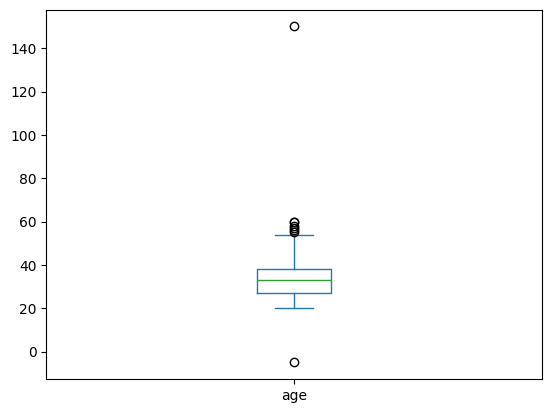

In [54]:
# Аномалии в возрасте, посмотрим сколько их 
age_anom = users[(users['age'] < 0) | (users['age'] > 100)]
print(f'Количество аномалий: {len(age_anom)}')
print(f'Доля аномалий от всего числа записей: {len(age_anom) / len(users)}')
users['age'].plot(kind='box')

In [68]:
age_anom

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [71]:
# Всего два выброса, заменим на NaN
users.loc[age_anom.index, 'age'] = np.nan

<Axes: >

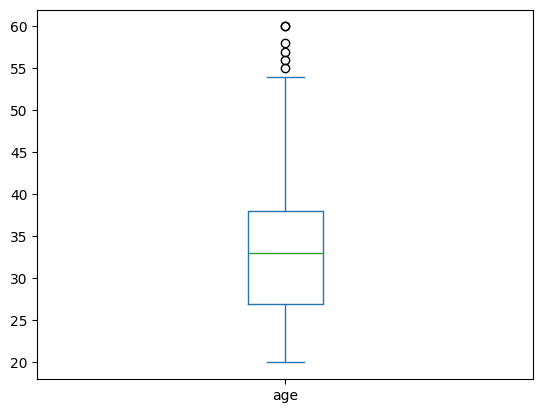

In [72]:
users['age'].plot(kind='box')

In [75]:
# Посмотрим payments
print(payments.info())
print(payments.describe())
payments.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB
None
         payment_id      user_id                   step1_opened  \
count   2661.000000  2660.000000                           2661   
mean    6433.978579  1760.884211  2024-04-15 17:56:46.854565888   
min     5001.000000  1001.000000            2024-04-01 00:19:00   
25%     5666.000000  1388.000000            2024-04-08 01:30:

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [80]:
payments[payments['user_id'].isna()]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [81]:
payments.isna().sum()

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

In [84]:
# Удаляем пропуск и меняем тип столбца
payments = payments.dropna(subset=['user_id'])
payments['user_id'] = payments['user_id'].astype('int64')
print(f"Дубликатов payment_id: {payments['payment_id'].duplicated().sum()}")

Дубликатов payment_id: 0


In [85]:
mask_invalid_step4 = payments['step4_success'].notna() & payments['step3_confirmed'].isna()
mask_invalid_step3 = payments['step3_confirmed'].notna() & payments['step2_entered'].isna()
mask_invalid_step2 = payments['step2_entered'].notna() & payments['step1_opened'].isna()

print(f"Строк, где step4 есть, а step3 нет: {mask_invalid_step4.sum()}")
print(f"Строк, где step3 есть, а step2 нет: {mask_invalid_step3.sum()}")
print(f"Строк, где step2 есть, а step1 нет: {mask_invalid_step2.sum()}")

Строк, где step4 есть, а step3 нет: 0
Строк, где step3 есть, а step2 нет: 0
Строк, где step2 есть, а step1 нет: 0


In [87]:
# Проверяем минимальную и максимальную дату по всем шагам
for col in ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']:
    print(f"{col}: min={payments[col].min()}, max={payments[col].max()}")

step1_opened: min=2024-04-01 00:19:00, max=2024-04-30 23:17:00
step2_entered: min=2024-04-01 00:23:00, max=2024-04-30 23:20:00
step3_confirmed: min=2024-04-01 00:29:00, max=2024-04-30 23:25:00
step4_success: min=2024-04-01 00:33:00, max=2024-04-30 23:30:00


In [88]:
users_in_payments = set(payments['user_id'])
users_in_users = set(payments['user_id'])

# Юзеры, которые платили, но их нет в базе пользователей
unknown_users = users_in_payments - users_in_users
print(f"Юзеров в платежах, которых нет в базе: {len(unknown_users)}")

Юзеров в платежах, которых нет в базе: 0


In [90]:
users_without_payments = users_in_users - users_in_payments
print(f"Юзеров в базе без платежей: {len(users_without_payments)}")

Юзеров в базе без платежей: 0


In [112]:
# Проверяем, есть ли у одного user_id разные группы в payments
split_check = payments.groupby('user_id')['group'].nunique()
bad_split_users = split_check[split_check > 1].index
print(f"Пользователей с двумя группами: {len(bad_split_users)}")

Пользователей с двумя группами: 0


In [113]:
# Пользователь попал в две группы по ошибке, такого удаляем
payments[payments['user_id'] == bad_split_users[0]]

IndexError: index 0 is out of bounds for axis 0 with size 0

In [117]:
# Удаляем все его записи из платежей
payments = payments[~payments['user_id'].isin(bad_split_users)]

# Удаляем его из таблицы пользователей (чтобы он не попал в знаменатель конверсии)
users = users[~users['user_id'].isin(bad_split_users)]

# Проверка
print(f"Проверка после удаления: {payments.groupby('user_id')['group'].nunique().max()}")

Проверка после удаления: 1


#### Данные подготовленны, следующие шаги

In [118]:
users.head()

,user_id,group,age,city,device_type
0,1001,A,31.0,Москва,ios
1,1002,A,31.0,Москва,ios
2,1003,A,25.0,Москва,android
3,1004,A,20.0,Москва,ios
4,1005,A,34.0,Москва,ios


In [119]:
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [124]:
for i in range(1001, 2000):
    if len(payments[payments['user_id'] == i]) > 2:
        res = payments[payments['user_id'] == i]
        break
res

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
3,5004,1004,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
5,5006,1004,A,2024-04-24 17:26:00,2024-04-24 17:27:00,2024-04-24 17:30:00,2024-04-24 17:36:00


In [125]:
# Так как в платежах у одного пользователя может быть несколько попыток, схлопним данные в построчный вариант с необходимой информацией
payments['is_success'] = payments['step4_success'].notna().astype(int)

user_level = payments.groupby('user_id').agg(
    group=('group', 'first'),
    # 1. Основная метрика: был ли хотя бы один успех (1/0)
    has_success=('is_success', 'max'),
    # 2. Сколько всего попыток было у пользователя
    total_attempts=('payment_id', 'count'),
    # 3. Сколько успешных попыток было у пользователя
    successful_attempts=('is_success', 'sum'),
    # 4. Доля успешных попыток у этого пользователя (от 0 до 1)
    success_rate_per_user=('is_success', 'mean')
).reset_index()

In [133]:
print(user_level.head(2))
users.shape

   user_id group  has_success  total_attempts  successful_attempts  \
0     1001     A            0               1                    0   
1     1002     A            0               1                    0   

   success_rate_per_user  
0                    0.0  
1                    0.0  


(1501, 5)

In [135]:
# Мерджим таблицы с LEFT чтобы учесть всех юзеров из users(1501). В данном случае разница 1 не особо критична, но если 
# будет много пользователей зарегестрированных в сервисе, но не совершивших платеж, и мы не учтем их в мердже то сильно завысим конверсию
final_df = users.merge(user_level, on='user_id', how='left')

# 2. Проверяем, сколько пользователей не сделали ни одной попытки
no_attempts = final_df['total_attempts'].isna().sum()
print(f"Пользователей без попыток оплаты: {no_attempts}")

Пользователей без попыток оплаты: 2


In [139]:
cols_to_fill = ['has_success', 'total_attempts', 'successful_attempts', 'success_rate_per_user']
final_df[cols_to_fill] = final_df[cols_to_fill].fillna(0)

# Приводим типы к int (чтобы не было 0.0)
final_df['has_success'] = final_df['has_success'].astype(int)
final_df['total_attempts'] = final_df['total_attempts'].astype(int)
final_df['successful_attempts'] = final_df['successful_attempts'].astype(int)

In [141]:
final_df.columns

Index(['user_id', 'group_x', 'age', 'city', 'device_type', 'group_y',
       'has_success', 'total_attempts', 'successful_attempts',
       'success_rate_per_user'],
      dtype='object')

In [142]:
final_df = final_df.rename(columns={'has_success': 'max_step_reached'})
final_df = final_df.drop(columns=['group_y'])  # удаляем дубль группы из платежей
final_df = final_df.rename(columns={'group_x': 'group'})

In [143]:
final_df

,user_id,group,age,city,device_type,max_step_reached,total_attempts,successful_attempts,success_rate_per_user
0,1001,A,31.0,Москва,ios,0,1,0,0.000000
1,1002,A,31.0,Москва,ios,0,1,0,0.000000
2,1003,A,25.0,Москва,android,0,1,0,0.000000
3,1004,A,20.0,Москва,ios,1,3,2,0.666667
4,1005,A,34.0,Москва,ios,1,2,1,0.500000
...,...,...,...,...,...,...,...,...,...
1496,2498,B,28.0,СПб,ios,1,1,1,1.000000
1497,2499,B,42.0,Москва,ios,1,3,3,1.000000
1498,2500,B,39.0,Москва,ios,0,1,0,0.000000
1499,9002,A,NaN,СПб,android,0,0,0,0.000000


In [144]:
final_df['group'].value_counts(dropna=False)

group
B    751
A    750
Name: count, dtype: int64

In [145]:
conversion_stats = final_df.groupby('group')['max_step_reached'].agg(['sum', 'count', 'mean'])
conversion_stats.columns = ['Успешные', 'Всего', 'Конверсия']
conversion_stats['Конверсия_%'] = (conversion_stats['Конверсия'] * 100).round(2)

print(conversion_stats)

       Успешные  Всего  Конверсия  Конверсия_%
group                                         
A           492    750   0.656000        65.60
B           603    751   0.802929        80.29


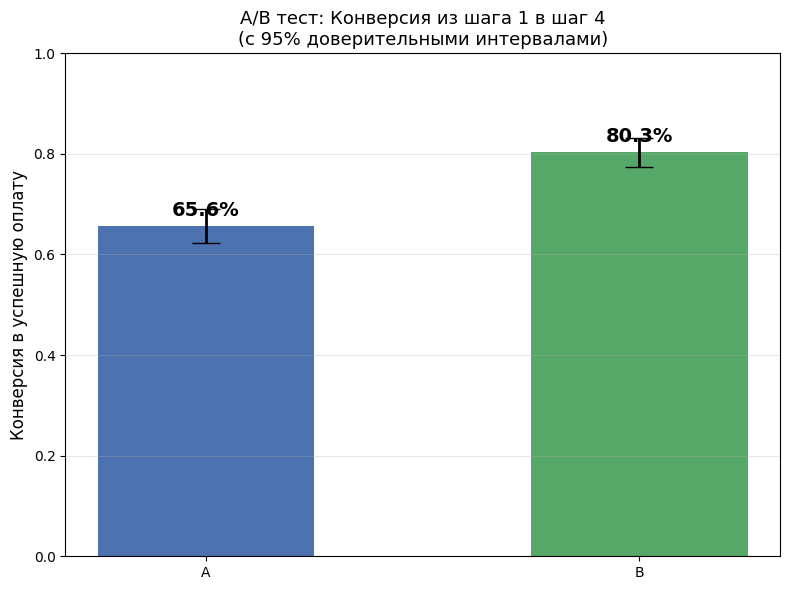

In [151]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Данные из таблицы
groups = ['A', 'B']
success = [492, 603]
total = [750, 751]
conv = [492/750, 603/751]

# Считаем 95% доверительные интервалы (используем формулу для пропорций)
z_crit = 1.96
ci_lower = []
ci_upper = []
for s, n in zip(success, total):
    p = s / n
    se = np.sqrt(p * (1 - p) / n)
    ci_lower.append(p - z_crit * se)
    ci_upper.append(p + z_crit * se)

# Строим график
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(groups, conv, color=['#4C72B0', '#55A868'], width=0.5, 
              yerr=[np.array(conv) - np.array(ci_lower), np.array(ci_upper) - np.array(conv)],
              capsize=10, error_kw={'elinewidth': 2, 'ecolor': 'black'})


for i, (bar, c) in enumerate(zip(bars, conv)):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
            f'{c*100:.1f}%', ha='center', fontsize=14, fontweight='bold')

ax.set_ylabel('Конверсия в успешную оплату', fontsize=12)
ax.set_title('A/B тест: Конверсия из шага 1 в шаг 4\n(с 95% доверительными интервалами)', fontsize=13)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Так как метрика бинарная (успех/неуспех), выборки независимые и достаточно большие, используется Z-тест для двух пропорций. Альтернатива — тест хи-квадрат Пирсона, который даст эквивалентный результат для таблицы 2×2

In [157]:
# Данные
count = np.array([492, 603])  # успешные
nobs = np.array([750, 751])    # всего

# Z-test
z_stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')

# Разница конверсий и доверительный интервал для разницы
p_A = count[0] / nobs[0]
p_B = count[1] / nobs[1]
lift = p_B - p_A

print(f"Конверсия A: {p_A:.4f} ({p_A*100:.2f}%)")
print(f"Конверсия B: {p_B:.4f} ({p_B*100:.2f}%)")
print(f"Абсолютный прирост (Lift): {lift:.4f} ({lift*100:.2f} п.п.)")
print(f"Относительный прирост: {(p_B/p_A - 1)*100:.2f}%")
print(f"Z-статистика: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

# Доверительный интервал для разницы
se_diff = np.sqrt(p_A*(1-p_A)/nobs[0] + p_B*(1-p_B)/nobs[1])
ci_diff = (lift - 1.96*se_diff, lift + 1.96*se_diff)
print(f"95% ДИ для разницы: ({ci_diff[0]*100:.2f} п.п.; {ci_diff[1]*100:.2f} п.п.)")

Конверсия A: 0.6560 (65.60%)
Конверсия B: 0.8029 (80.29%)
Абсолютный прирост (Lift): 0.1469 (14.69 п.п.)
Относительный прирост: 22.40%
Z-статистика: -6.4074
P-value: 0.000000
95% ДИ для разницы: (10.26 п.п.; 19.13 п.п.)


p << 0.05 следовательно можно считать прирост в конверсии статистически значимым

In [159]:
users['city'].unique()

array(['Москва', 'Регион', 'СПб'], dtype=object)

In [163]:
# Кросс-таблица: группа × устройство
device_crosstab = pd.crosstab(final_df['group'], final_df['device_type'])
print("Распределение устройств по группам:")
print(device_crosstab)

# Доли (в процентах) для наглядности
device_pct = pd.crosstab(final_df['group'], final_df['device_type'], normalize='index') * 100
print("\nДоли устройств (%):")
print(device_pct.round(1))

# Хи-квадрат тест на независимость
chi2, p_val, dof, expected = chi2_contingency(device_crosstab)
print(f"\nChi-square p-value: {p_val:.4f}")
if p_val > 0.05:
    print("Распределение устройств по группам статистически не различается — сплит корректный.")
else:
    print("Есть статистические различия в распределении устройств — возможен bias сплита!")

Распределение устройств по группам:
device_type  android  ios
group                    
A                406  344
B                369  382

Доли устройств (%):
device_type  android   ios
group                     
A               54.1  45.9
B               49.1  50.9

Chi-square p-value: 0.0593
Распределение устройств по группам статистически не различается — сплит корректный.


In [164]:
# Конверсия по группам и устройствам
device_conv = final_df.groupby(['device_type', 'group'])['max_step_reached'].agg(
    ['sum', 'count', 'mean']
).reset_index()
device_conv.columns = ['Устройство', 'Группа', 'Успешные', 'Всего', 'Конверсия']
device_conv['Конверсия_%'] = (device_conv['Конверсия'] * 100).round(1)

print(device_conv)

  Устройство Группа  Успешные  Всего  Конверсия  Конверсия_%
0    android      A       261    406   0.642857         64.3
1    android      B       295    369   0.799458         79.9
2        ios      A       231    344   0.671512         67.2
3        ios      B       308    382   0.806283         80.6


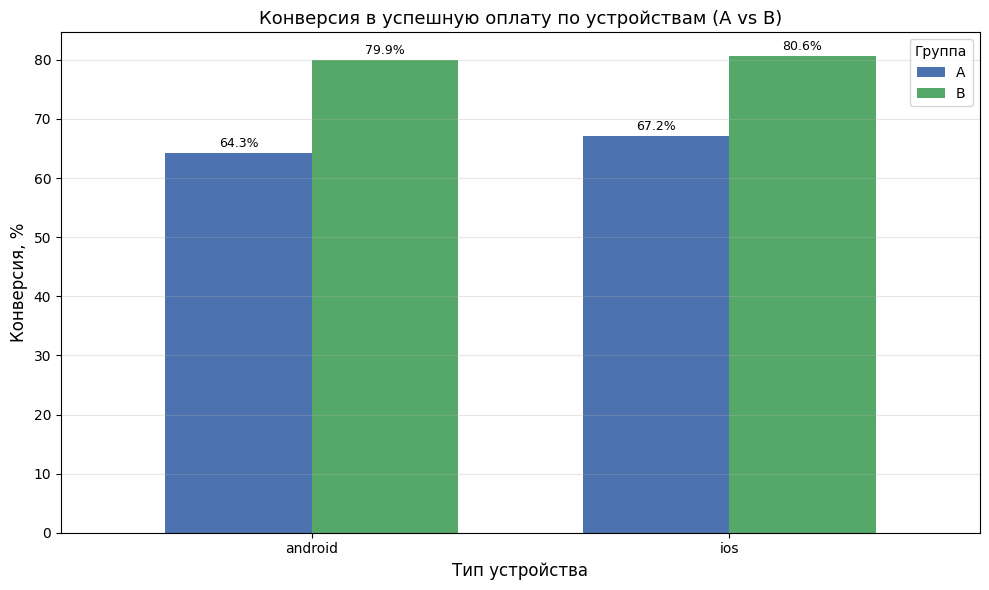

In [165]:


# Готовим данные для графика
pivot_conv = final_df.pivot_table(
    index='device_type', 
    columns='group', 
    values='max_step_reached', 
    aggfunc='mean'
) * 100

# Строим grouped bar chart
pivot_conv.plot(kind='bar', figsize=(10, 6), color=['#4C72B0', '#55A868'], width=0.7)
plt.title('Конверсия в успешную оплату по устройствам (A vs B)', fontsize=13)
plt.ylabel('Конверсия, %', fontsize=12)
plt.xlabel('Тип устройства', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Группа')
plt.grid(axis='y', alpha=0.3)

# Добавляем подписи значений
for i, (idx, row) in enumerate(pivot_conv.iterrows()):
    for j, val in enumerate(row):
        if not pd.isna(val):
            plt.text(i + (j - 0.5) * 0.35, val + 1, f'{val:.1f}%', 
                     ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [166]:
from statsmodels.stats.proportion import proportions_ztest

print("Z-test по сегментам устройств:\n")
for device in final_df['device_type'].dropna().unique():
    subset = final_df[final_df['device_type'] == device]
    counts = subset.groupby('group')['max_step_reached'].agg(['sum', 'count'])
    
    if len(counts) == 2:  # есть обе группы
        successes = counts['sum'].values
        nobs = counts['count'].values
        z, p = proportions_ztest(successes, nobs)
        
        lift = (successes[1]/nobs[1]) - (successes[0]/nobs[0])
        print(f"{device}:")
        print(f"  A: {successes[0]}/{nobs[0]} = {successes[0]/nobs[0]*100:.1f}%")
        print(f"  B: {successes[1]}/{nobs[1]} = {successes[1]/nobs[1]*100:.1f}%")
        print(f"  Lift: {lift*100:+.1f} п.п. | p-value: {p:.4f}")
        print(f"  {'✅ Значимо' if p < 0.05 else '❌ Не значимо'}\n")

Z-test по сегментам устройств:

ios:
  A: 231/344 = 67.2%
  B: 308/382 = 80.6%
  Lift: +13.5 п.п. | p-value: 0.0000
  ✅ Значимо

android:
  A: 261/406 = 64.3%
  B: 295/369 = 79.9%
  Lift: +15.7 п.п. | p-value: 0.0000
  ✅ Значимо



In [169]:
final_df

,user_id,group,age,city,device_type,max_step_reached,total_attempts,successful_attempts,success_rate_per_user
0,1001,A,31.0,Москва,ios,0,1,0,0.000000
1,1002,A,31.0,Москва,ios,0,1,0,0.000000
2,1003,A,25.0,Москва,android,0,1,0,0.000000
3,1004,A,20.0,Москва,ios,1,3,2,0.666667
4,1005,A,34.0,Москва,ios,1,2,1,0.500000
...,...,...,...,...,...,...,...,...,...
1496,2498,B,28.0,СПб,ios,1,1,1,1.000000
1497,2499,B,42.0,Москва,ios,1,3,3,1.000000
1498,2500,B,39.0,Москва,ios,0,1,0,0.000000
1499,9002,A,NaN,СПб,android,0,0,0,0.000000
